# Mandatory assignment 3

**GitHub repository:** [https://github.com/dorica5/tech2-assignment3](https://github.com/dorica5/tech2-assignment3)

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

In [1]:
import numpy as npp
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [2]:
df = pd.read_csv("SCF_10pct.csv")

print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB
None


In [3]:
column_names = df.columns.to_list()

for column_name in column_names:
    total_before = len(df)
    df = df.dropna(subset=[column_name])
    total_now = len(df)
    total_dropped = total_before - total_now
    
    print(f"Column : {column_name}. Dropped: {total_dropped}. Now: {total_now}")

Column : id. Dropped: 0. Now: 5808
Column : year. Dropped: 0. Now: 5808
Column : age. Dropped: 0. Now: 5808
Column : educ. Dropped: 16. Now: 5792
Column : stocks. Dropped: 18. Now: 5774
Column : equity. Dropped: 16. Now: 5758


In [4]:
total_before = len(df)
df = df[df["age"].between(25, 89)]
total_after = len(df)
total_dropped = total_before - total_after
print(f"Dropped: {total_dropped}. Now: {total_after}")

Dropped: 326. Now: 5432


In [5]:
df.loc[df["stocks"] > 0, "direct"] = 1
df.loc[df["stocks"] <= 0, "direct"] = 0

df.loc[df["equity"] > 0, "overall"] = 1
df.loc[df["equity"] <= 0, "overall"] = 0

In [6]:
print(df.info())

<class 'pandas.DataFrame'>
Index: 5432 entries, 0 to 5807
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       5432 non-null   int64  
 1   year     5432 non-null   int64  
 2   age      5432 non-null   int64  
 3   educ     5432 non-null   float64
 4   stocks   5432 non-null   float64
 5   equity   5432 non-null   float64
 6   direct   5432 non-null   float64
 7   overall  5432 non-null   float64
dtypes: float64(5), int64(3)
memory usage: 381.9 KB
None


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [7]:
def participation_rate(indicator):
    total = 0
    for number in indicator:
        total += number
    
    fraction = total / len(indicator)
    percent = fraction * 100 
    return percent


my_direct_rate = participation_rate(df["direct"])
my_overall_rate = participation_rate(df["overall"])

pd_direct_rate = df["direct"].mean() * 100
pd_overall_rate = df["overall"].mean() * 100

print(f"My direct rate: {my_direct_rate:.1f}%. My overall rate: {my_overall_rate:.1f}%")
print(f"Pd direct rate: {pd_direct_rate:.1f}%. Pd overall rate: {pd_overall_rate:.1f}%")


My direct rate: 17.0%. My overall rate: 49.4%
Pd direct rate: 17.0%. Pd overall rate: 49.4%


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

In [8]:
direct_list = []
overall_list = []
categories = [1,2,3,4]
for category in categories:
    direct_rate = participation_rate(df.loc[df["educ"] == category, "direct"])
    overall_rate = participation_rate(df.loc[df["educ"] == category, "overall"])
    
    direct_list.append(round(direct_rate, 1))
    overall_list.append(round(overall_rate, 1))

print(pd.DataFrame({"Education": categories, "direct": direct_list, "Overall": overall_list}))
    

   Education  direct  Overall
0          1     4.4     17.3
1          2    11.4     39.9
2          3    13.5     48.3
3          4    30.5     73.5


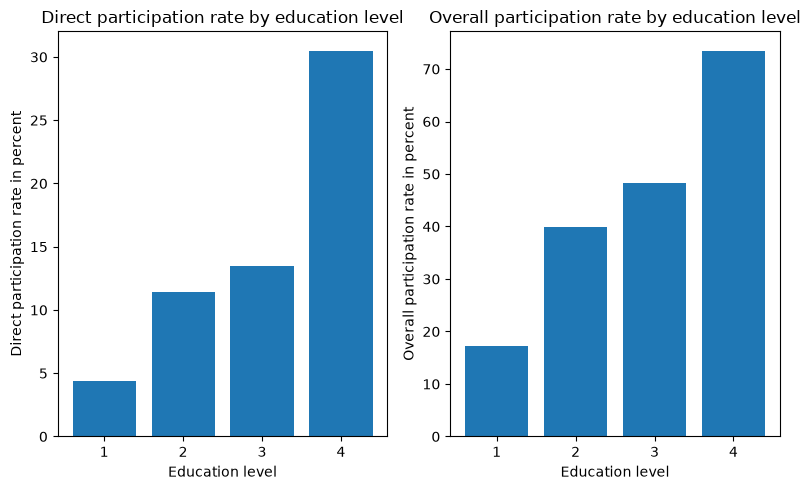

In [9]:
fig, axes = plt.subplots(1, 2, figsize = (8, 5))

axes[0].bar(categories, direct_list)
axes[0].set_title("Direct participation rate by education level")
axes[0].set_xlabel("Education level")
axes[0].set_ylabel("Direct participation rate in percent")



axes[1].bar(categories, overall_list)
axes[1].set_title("Overall participation rate by education level")
axes[1].set_xlabel("Education level")
axes[1].set_ylabel("Overall participation rate in percent")

plt.tight_layout()
plt.show()

#### The answer
We can see from the figure above that the participation rates, both direct and overall, rises with every education level. This shows us that those with higher education are more likely to hold stocks than those with lower education. This is more clear when we look at the different in direct participation rates between 1 and 2, and 3 and 4 where the increase is more than half.

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

In [10]:
years = df["year"].unique().tolist()

print(years)

direct_list_over_time = []
overall_list_over_time = []

for year in years:
    direct_rate = participation_rate(df.loc[df["year"] == year, "direct"])
    overall_rate = participation_rate(df.loc[df["year"] == year, "overall"])
    
    direct_list_over_time.append(round(direct_rate, 1))
    overall_list_over_time.append(round(overall_rate, 1))
    
print(pd.DataFrame({"Years" : years, "Direct" : direct_list_over_time, "Overall" : overall_list_over_time}))

[1989, 1992, 1995, 1998, 2001, 2004, 2007, 2010, 2013, 2016, 2019, 2022]
    Years  Direct  Overall
0    1989    15.6     31.6
1    1992    18.3     40.1
2    1995    15.7     45.9
3    1998    19.9     51.2
4    2001    21.8     57.0
5    2004    18.9     54.7
6    2007    17.3     56.5
7    2010    17.4     50.3
8    2013    14.8     49.9
9    2016    12.3     52.0
10   2019    12.4     49.8
11   2022    19.2     54.3


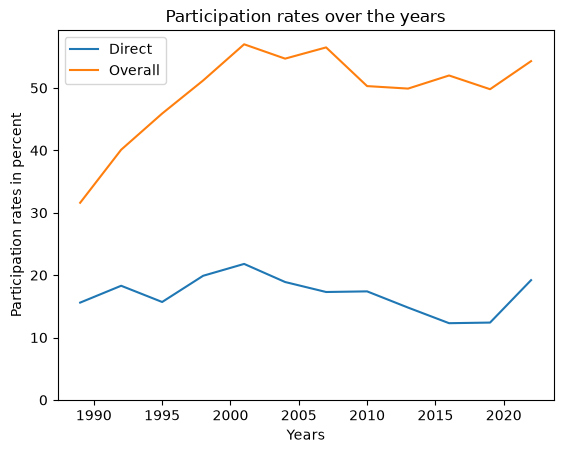

In [11]:

plt.plot(years, direct_list_over_time, label= "Direct")
plt.plot(years, overall_list_over_time, label="Overall")

plt.title("Participation rates over the years")
plt.xlabel("Years")
plt.ylabel("Participation rates in percent")
plt.ylim(0)
plt.legend()

plt.show()

In [12]:
direct_percentage_point = round(direct_list_over_time[-1] - direct_list_over_time[0],1)
overall_percentage_point = round(overall_list_over_time[-1] - overall_list_over_time[0],1)

print(f"Change in direct participation: {direct_percentage_point}. Change in overall participation: {overall_percentage_point}")

Change in direct participation: 3.6. Change in overall participation: 22.7


##### The answer
We can see that there are fluctuations in both lines. We see there's a sharp rise up until about 2001, then a decline happens, probably due to the dot com bubble burst. We see the same thing in overall where there's a definite decline happening, probably due to the 2008 financial crisis, and we see a rise in 2020 and and onwards which could be because of the markets that were booking during Covid.

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

There was no use of AI during this assignment.